# Fleet Force | Diagnóstico de eficiência de combustível

### Estudo exploratório com dados públicos brasileiros

O **Fleet Force** busca ajudar gestores a entender os custos de uma frota, comparar despesas e identificar oportunidades de economia. Este estudo investiga uma parte concreta desse desafio: **como reconhecer veículos que aparentam consumir mais combustível do que outros veículos comparáveis?**

A proposta é converter registros de quilometragem e despesas em indicadores acessíveis para a tomada de decisão. Não se trata de uma auditoria de abastecimento nem de um modelo preditivo de inteligência artificial: esta versão aplica **comparações estatísticas e critérios transparentes de análise**.

**Perguntas que orientam o estudo:**

- Quais veículos apresentam menor eficiência dentro de um grupo do mesmo modelo?
- É possível identificar situações que merecem investigação antes de gerarem mais custos?
- Como os resultados se comparam com referências públicas de consumo?
- Qual seria o valor aproximado do consumo excedente em um cenário de preços de combustível?

**Fontes utilizadas**

| Base | O que fornece | Papel na análise |
| --- | --- | --- |
| Relatório de despesas de veículos da **UFMG (2025)** | Identificação, modelos, quilometragem e despesas | Frota de referência para o estudo |
| **Inmetro — PBEV 2026** | Consumo padronizado de veículos leves | Referência pública complementar |
| **ANP — Preços semestrais, 1º semestre de 2026** | Preços observados de combustíveis | Simulação financeira, sem reconstruir gastos históricos |

> **Leitura correta:** uma diferença de consumo é um **indício para investigação**, não prova de desperdício. Idade do veículo, trajeto, carga, manutenção, combustível e qualidade dos registros podem explicar diferenças.

---

**Navegação:** preparação dos dados → validação → comparação entre veículos → comparação pública → cenário financeiro → resultados e gráficos → conclusões.

**Como executar:** mantenha os três arquivos originais na pasta do notebook, instale as dependências na primeira célula e execute as células em ordem. Os gráficos e tabelas incluídos no arquivo são uma fotografia da última execução; podem mudar ao atualizar os dados.


In [1]:
%pip install -q "pillow<13" pdfplumber pandas numpy matplotlib

from pathlib import Path
import math
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 1. Preparação do ambiente

Esta etapa importa as bibliotecas usadas para ler os relatórios, organizar as informações e desenhar os gráficos. A instalação abaixo funciona em ambientes Jupyter que oferecem acesso ao gerenciador de pacotes Python.


In [2]:
# Os arquivos de entrada devem estar na mesma pasta do notebook.
SEARCH_DIRS = [Path.cwd()]

PBEV_FILENAME = "Tabela PBEV 2026_25_AGO.pdf"
FLEET_FILENAME = "despesa-veiculos-ufmg-2025.pdf"
ANP_FILENAME = "Preços semestrais - AUTOMOTIVOS_2026.01.csv"

# Critérios adotados nesta análise exploratória.
MIN_DISTANCE_KM = 500
MIN_MODEL_PEERS = 3
MAX_PLAUSIBLE_KMPL = 30.0

# Tolerância mínima para sinalização diante do PBEV.
PBEV_TOLERANCE = 0.20

# Limiares para comparação entre veículos do mesmo modelo.
PEER_MODERATE_OVERUSE = 0.10
PEER_HIGH_OVERUSE = 0.25

ANP_STATE = "MG"


def find_input_file(filename: str) -> Path:
    for directory in SEARCH_DIRS:
        candidate = directory / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Não foi possível encontrar {filename!r}. Coloque o arquivo na mesma pasta "
        "deste notebook ou atualize SEARCH_DIRS."
    )


PBEV_PATH = find_input_file(PBEV_FILENAME)
FLEET_PATH = find_input_file(FLEET_FILENAME)
ANP_PATH = find_input_file(ANP_FILENAME)

DATA_DIR = FLEET_PATH.parent
OUTPUT_DIR = DATA_DIR / "fleet_analysis_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print("PBEV:", PBEV_PATH)
print("Frota:", FLEET_PATH)
print("ANP:", ANP_PATH)
print("Saídas:", OUTPUT_DIR)


PBEV: /content/Tabela PBEV 2026_25_AGO.pdf
Frota: /content/despesa-veiculos-ufmg-2025.pdf
ANP: /content/Preços semestrais - AUTOMOTIVOS_2026.01.csv
Saídas: /content/fleet_analysis_outputs


## 2. Preparação e padronização das informações

Relatórios públicos nem sempre chegam em um formato pronto para análise. As funções abaixo corrigem formatos numéricos, padronizam a escrita dos nomes e organizam a apresentação das tabelas. Esses cuidados evitam que diferenças de formatação sejam confundidas com diferenças entre veículos.


In [3]:
def normalize_text(value) -> str:
    value = "" if value is None else str(value)
    value = unicodedata.normalize("NFKD", value)
    value = "".join(ch for ch in value if not unicodedata.combining(ch))
    value = value.upper().replace("&", " AND ")
    value = re.sub(r"[^A-Z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()


def parse_us_number(value):
    """Fleet PDF uses values such as 3,650.38."""
    value = "" if value is None else str(value).strip()
    if not value:
        return np.nan
    try:
        return float(value.replace(",", ""))
    except ValueError:
        return np.nan


def parse_br_decimal(value):
    """PBEV uses decimal comma such as 14,5."""
    value = "" if value is None else str(value).strip()
    if not value or value in {"\\", "-", "ND", "N.A."}:
        return np.nan
    try:
        return float(value.replace(".", "").replace(",", "."))
    except ValueError:
        return np.nan


DISPLAY_COLUMN_LABELS_PT = {
    "fleet_id": "Identificador do veículo",
    "model": "Modelo",
    "os_count": "Quantidade de OS",
    "labor_internal": "Mão de obra interna",
    "labor_external": "Mão de obra externa",
    "parts": "Peças",
    "tires": "Pneus",
    "fuel_expense": "Despesa com combustível",
    "lubricant": "Lubrificante",
    "wash": "Lavagem",
    "km": "Distância (km)",
    "kmpl_reported": "KM/L informado",
    "total_expense": "Despesa total",
    "cost_per_km": "Custo por km",
    "source_page": "Página de origem",
    "liters_est": "Litros estimados",
    "kmpl": "KM/L calculado",
    "model_norm": "Modelo normalizado",
    "quality_reason": "Motivo de qualidade",
    "valid_efficiency": "Eficiência válida",
    "model_peer_count": "Veículos comparáveis do mesmo modelo",
    "model_peer_median_kmpl": "Mediana KM/L do mesmo modelo",
    "model_peer_mean_kmpl": "Média KM/L do mesmo modelo",
    "model_peer_q25_kmpl": "Q1 KM/L do mesmo modelo",
    "model_peer_q75_kmpl": "Q3 KM/L do mesmo modelo",
    "peer_efficiency_ratio": "Razão de eficiência vs. mesmo modelo",
    "peer_overuse_pct": "Excesso de consumo vs. mesmo modelo",
    "excess_liters_vs_peer": "Litros excedentes vs. mesmo modelo",
    "normalized_efficiency_percentile": "Percentil de eficiência normalizada",
    "peer_status": "Status vs. mesmo modelo",
    "category": "Categoria",
    "brand": "Marca",
    "version": "Versão",
    "motor": "Motor",
    "propulsion": "Propulsão",
    "transmission": "Transmissão",
    "air_cond": "Ar-condicionado",
    "steering": "Direção",
    "fuel_code": "Código de combustível",
    "ethanol_city": "Etanol urbano (km/L)",
    "ethanol_highway": "Etanol rodoviário (km/L)",
    "ethanol_combined": "Etanol combinado (km/L)",
    "gas_city": "Gasolina urbano (km/L)",
    "gas_highway": "Gasolina rodoviário (km/L)",
    "gas_combined": "Gasolina combinado (km/L)",
    "energy_mj_km": "Consumo energético (MJ/km)",
    "electric_range_km": "Autonomia elétrica (km)",
    "pbev_model": "Modelo PBEV",
    "pbev_brand": "Marca PBEV",
    "pbev_category": "Categoria PBEV",
    "pbev_fuel_codes": "Códigos de combustível PBEV",
    "pbev_reference_count": "Quantidade de referências PBEV",
    "pbev_min_kmpl": "KM/L mínimo PBEV",
    "pbev_median_kmpl": "KM/L mediano PBEV",
    "pbev_max_kmpl": "KM/L máximo PBEV",
    "pbev_model_norm": "Modelo PBEV normalizado",
    "pbev_match_method": "Método de associação PBEV",
    "public_overuse_pct_vs_min": "Excesso de consumo vs. PBEV conservador",
    "excess_liters_vs_public_min": "Litros excedentes vs. PBEV conservador",
    "public_waste_flag": "Sinalizado por desperdício vs. PBEV",
    "sale_price": "Preço de venda",
    "collection_date": "Data da coleta",
    "count": "Registros",
    "mean": "Média",
    "median": "Mediana",
    "min": "Mínimo",
    "max": "Máximo",
    "rows": "Registros",
    "peer_excess_cost_gasolina": "Custo excedente vs. pares — gasolina",
    "peer_excess_cost_etanol": "Custo excedente vs. pares — etanol",
    "peer_excess_cost_diesel_s10": "Custo excedente vs. pares — diesel S10",
    "public_excess_cost_gasolina": "Custo excedente vs. PBEV — gasolina",
    "public_excess_cost_etanol": "Custo excedente vs. PBEV — etanol",
    "public_excess_cost_diesel_s10": "Custo excedente vs. PBEV — diesel S10",
    "excess_liters_positive": "Litros excedentes estimados",
}

QUALITY_REASON_LABELS_PT = {
    "zero_distance": "distância zero",
    "low_distance": "distância insuficiente",
    "implausibly_low_kmpl": "KM/L implausivelmente baixo",
    "implausibly_high_kmpl": "KM/L implausivelmente alto",
    "missing_kmpl": "KM/L ausente",
}

PEER_STATUS_LABELS_PT = {
    "invalid_or_insufficient_distance": "dados inválidos ou distância insuficiente",
    "insufficient_same_model_peers": "comparáveis do mesmo modelo insuficientes",
    "high_waste_vs_same_model": "alto desperdício vs. mesmo modelo",
    "moderate_waste_vs_same_model": "desperdício moderado vs. mesmo modelo",
    "slightly_below_same_model": "ligeiramente abaixo do mesmo modelo",
    "at_or_better_than_same_model": "igual ou melhor que o mesmo modelo",
}

PBEV_MATCH_METHOD_LABELS_PT = {
    "excluded_non_light_or_generic": "excluído: veículo não leve ou rótulo genérico",
    "exact": "correspondência exata",
    "contained_model_name": "nome do modelo contido no rótulo",
    "contained_model_token": "token do modelo contido no rótulo",
    "no_safe_match": "sem correspondência segura",
}


def translate_quality_reason(value: str) -> str:
    if not isinstance(value, str) or not value:
        return value
    reasons = [item for item in value.split(";") if item]
    return "; ".join(QUALITY_REASON_LABELS_PT.get(item, item) for item in reasons)


def localize_table(data: pd.DataFrame) -> pd.DataFrame:
    """Translate presentation labels without changing the analytical data model."""
    localized = data.copy()

    if "quality_reason" in localized.columns:
        localized["quality_reason"] = localized["quality_reason"].map(translate_quality_reason)

    if "peer_status" in localized.columns:
        localized["peer_status"] = localized["peer_status"].map(
            lambda value: PEER_STATUS_LABELS_PT.get(value, value)
        )

    if "pbev_match_method" in localized.columns:
        localized["pbev_match_method"] = localized["pbev_match_method"].map(
            lambda value: PBEV_MATCH_METHOD_LABELS_PT.get(value, value)
        )

    for boolean_column in ["valid_efficiency", "public_waste_flag"]:
        if boolean_column in localized.columns:
            localized[boolean_column] = localized[boolean_column].map(
                {True: "Sim", False: "Não"}
            )

    localized = localized.rename(columns=DISPLAY_COLUMN_LABELS_PT)
    if localized.index.name in DISPLAY_COLUMN_LABELS_PT:
        localized.index.name = DISPLAY_COLUMN_LABELS_PT[localized.index.name]

    return localized


## 3. Conhecendo a frota analisada

O relatório de despesas da UFMG está em PDF. Aqui, suas tabelas são transformadas em registros que podem ser filtrados e comparados.

Depois da leitura, registros idênticos são desconsiderados para evitar contagem duplicada. Quando um veículo possui mais de uma linha de despesa, os valores são reunidos e a eficiência é recalculada. Assim, cada veículo pode ser analisado como uma unidade.

**O que observar na saída:** quantidade de linhas extraídas, duplicações encontradas e número de veículos distintos.


In [4]:
FLEET_BOUNDS = [35, 90, 180, 210, 260, 310, 360, 410, 455, 495, 545, 605, 655, 725, 780]
FLEET_COLUMNS = [
    "fleet_id", "model", "os_count", "labor_internal", "labor_external",
    "parts", "tires", "fuel_expense", "lubricant", "wash", "km",
    "kmpl_reported", "total_expense", "cost_per_km"
]


def _column_index(x, bounds):
    for i in range(len(bounds) - 1):
        if bounds[i] <= x < bounds[i + 1]:
            return i
    return None


def parse_fleet_pdf(path: Path) -> pd.DataFrame:
    rows = []

    with pdfplumber.open(path) as pdf:
        for page_number, page in enumerate(pdf.pages, start=1):
            words = page.extract_words(
                x_tolerance=1,
                y_tolerance=1.2,
                keep_blank_chars=False,
            )

            # A data row is anchored by a 7-character Brazilian fleet/plate ID.
            anchors = sorted({
                round(word["top"], 2)
                for word in words
                if 40 <= word["x0"] < 90
                and re.fullmatch(r"[A-Z0-9]{7}", word["text"])
            })

            for y in anchors:
                row_words = [
                    word for word in words
                    if abs(word["top"] - y) <= 0.8
                    and 35 <= word["x0"] < 780
                ]

                buckets = [[] for _ in FLEET_COLUMNS]
                for word in row_words:
                    x_center = (word["x0"] + word["x1"]) / 2
                    idx = _column_index(x_center, FLEET_BOUNDS)
                    if idx is not None:
                        buckets[idx].append(word)

                values = [
                    " ".join(
                        word["text"]
                        for word in sorted(bucket, key=lambda item: item["x0"])
                    ).strip()
                    for bucket in buckets
                ]

                if re.fullmatch(r"[A-Z0-9]{7}", values[0]):
                    record = dict(zip(FLEET_COLUMNS, values))
                    record["source_page"] = page_number
                    rows.append(record)

    df = pd.DataFrame(rows)

    numeric_columns = [c for c in FLEET_COLUMNS if c not in {"fleet_id", "model"}]
    for column in numeric_columns:
        df[column] = df[column].map(parse_us_number)

    return df


fleet_raw = parse_fleet_pdf(FLEET_PATH)

print(f"Linhas extraídas do relatório: {len(fleet_raw):,}")
print(f"Linhas exatamente duplicadas: {fleet_raw.duplicated(subset=FLEET_COLUMNS).sum():,}")
display(localize_table(fleet_raw.head()))


Linhas extraídas do relatório: 232
Linhas exatamente duplicadas: 1


,Identificador do veículo,Modelo,Quantidade de OS,Mão de obra interna,Mão de obra externa,Peças,Pneus,Despesa com combustível,Lubrificante,Lavagem,Distância (km),KM/L informado,Despesa total,Custo por km,Página de origem
0,EXY2I64,MASTER,1.00,19.57,0.00,401.48,0.00,"3,650.38",0.00,97.90,"4,431.00",8.77,"4,169.33",0.94,1
1,GMF1396,CAMINHAO,6.00,123.45,"3,454.33","15,579.99",0.00,"2,785.84",0.00,63.63,698.00,1.98,"22,007.24",31.53,1
2,GMF1756,VAN SPRINTER,0.00,0.00,0.00,0.00,0.00,"1,312.78",0.00,0.00,"1,165.00",5.64,"1,312.78",1.13,1
3,GMF2414,CAMINHAO,3.00,0.00,294.70,503.89,0.00,"7,789.40",0.00,127.27,"2,807.00",2.43,"8,715.26",3.10,1
4,GMF2794,CAMINHAO 608,0.00,0.00,0.00,0.00,0.00,"3,464.63",0.00,0.00,"4,235.00",7.93,"3,464.63",0.82,1


In [5]:
def aggregate_fleet_rows(df: pd.DataFrame):
    # Evita contar duas vezes um registro idêntico.
    clean = df.drop_duplicates(subset=FLEET_COLUMNS).copy()

    # Liters implied by the report's distance and KM/L.
    clean["liters_est"] = np.where(
        (clean["km"] > 0) & (clean["kmpl_reported"] > 0),
        clean["km"] / clean["kmpl_reported"],
        np.nan,
    )

    monetary_columns = [
        "labor_internal", "labor_external", "parts", "tires",
        "fuel_expense", "lubricant", "wash", "total_expense"
    ]

    aggregation = {column: "sum" for column in monetary_columns}
    aggregation.update({
        "os_count": "sum",
        "km": "sum",
        "liters_est": "sum",
        "model": "first",
    })

    fleet = clean.groupby("fleet_id", as_index=False).agg(aggregation)

    fleet["kmpl"] = fleet["km"] / fleet["liters_est"]
    fleet.loc[~np.isfinite(fleet["kmpl"]), "kmpl"] = np.nan
    fleet["cost_per_km"] = fleet["total_expense"] / fleet["km"].replace(0, np.nan)
    fleet["model_norm"] = fleet["model"].map(normalize_text)

    return clean, fleet


fleet_rows, fleet = aggregate_fleet_rows(fleet_raw)

print(f"Linhas após remoção de duplicatas exatas: {len(fleet_rows):,}")
print(f"Veículos únicos: {fleet['fleet_id'].nunique():,}")
display(localize_table(fleet.head()))


Linhas após remoção de duplicatas exatas: 231
Veículos únicos: 217


,Identificador do veículo,Mão de obra interna,Mão de obra externa,Peças,Pneus,Despesa com combustível,Lubrificante,Lavagem,Despesa total,Quantidade de OS,Distância (km),Litros estimados,Modelo,KM/L calculado,Custo por km,Modelo normalizado
0,EXY2I64,19.57,0.00,401.48,0.00,"3,650.38",0.00,97.90,"4,169.33",1.00,"4,431.00",505.25,MASTER,8.77,0.94,MASTER
1,GMF1396,123.45,"3,454.33","15,579.99",0.00,"2,785.84",0.00,63.63,"22,007.24",6.00,698.00,352.53,CAMINHAO,1.98,31.53,CAMINHAO
2,GMF1756,0.00,0.00,0.00,0.00,"1,312.78",0.00,0.00,"1,312.78",0.00,"1,165.00",206.56,VAN SPRINTER,5.64,1.13,VAN SPRINTER
3,GMF2414,0.00,294.70,503.89,0.00,"7,789.40",0.00,127.27,"8,715.26",3.00,"2,807.00","1,155.14",CAMINHAO,2.43,3.10,CAMINHAO
4,GMF2794,0.00,0.00,0.00,0.00,"3,464.63",0.00,0.00,"3,464.63",0.00,"4,235.00",534.05,CAMINHAO 608,7.93,0.82,CAMINHAO 608


## 4. Quais dados são confiáveis para comparação?

Antes de procurar veículos com alto consumo, verificamos quais registros possuem distância percorrida e indicadores coerentes. Distâncias muito baixas e valores extremos de quilômetros por litro podem distorcer toda a análise.

Nesta versão, só participam das comparações de eficiência os registros que atendem aos limites definidos na configuração. **Um registro excluído não significa que o veículo tem problema mecânico**; significa apenas que não há evidência suficiente para uma comparação segura.


In [6]:
fleet["quality_reason"] = ""

fleet.loc[fleet["km"] <= 0, "quality_reason"] += "zero_distance;"
fleet.loc[
    (fleet["km"] > 0) & (fleet["km"] < MIN_DISTANCE_KM),
    "quality_reason"
] += "low_distance;"

fleet.loc[
    fleet["kmpl"].notna() & (fleet["kmpl"] < 1),
    "quality_reason"
] += "implausibly_low_kmpl;"

fleet.loc[
    fleet["kmpl"].notna() & (fleet["kmpl"] > MAX_PLAUSIBLE_KMPL),
    "quality_reason"
] += "implausibly_high_kmpl;"

fleet.loc[fleet["kmpl"].isna(), "quality_reason"] += "missing_kmpl;"

fleet["valid_efficiency"] = (
    (fleet["km"] >= MIN_DISTANCE_KM)
    & fleet["kmpl"].between(1, MAX_PLAUSIBLE_KMPL)
)

quality_issues = fleet.loc[
    ~fleet["valid_efficiency"],
    ["fleet_id", "model", "km", "kmpl", "fuel_expense", "quality_reason"]
].sort_values(["quality_reason", "km"], ascending=[True, False])

print(f"Veículos válidos para análise de eficiência: {fleet['valid_efficiency'].sum():,} / {len(fleet):,}")
display(localize_table(quality_issues.head(30)))


Veículos válidos para análise de eficiência: 201 / 217


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Despesa com combustível,Motivo de qualidade
195,KIA7J65,ONIBUS K 112,"378,514.00",972.09,"2,488.14",KM/L implausivelmente alto
127,GMF7716,FLUENCE,"62,815.00",93.47,"4,361.62",KM/L implausivelmente alto
146,GMF7964,DOBLO - ELX,"41,358.00",84.14,"3,219.72",KM/L implausivelmente alto
124,GMF7576,SPACEFOX,424.00,9.28,292.09,distância insuficiente
206,QOW0028,MARCOPOLO,410.00,5.91,547.01,distância insuficiente
194,JKH9333,L200 GL,401.00,8.31,352.84,distância insuficiente
197,NYB3752,TANQUE,380.00,1.05,"2,862.41",distância insuficiente
18,GMF4738,PALIO,267.00,5.38,317.14,distância insuficiente
41,GMF5419,KOMBI -,253.00,5.04,339.16,distância insuficiente
40,GMF5418,KOMBI -,200.00,4.92,275.88,distância insuficiente


> **Leitura da etapa:** apenas os veículos considerados válidos seguem para os rankings de eficiência. O objetivo do filtro é evitar conclusões baseadas em medições frágeis.


> **Por que isso importa?** Um valor de km/L excepcionalmente alto pode resultar de inconsistências no hodômetro, no abastecimento ou no próprio registro. A análise evita premiar automaticamente esses casos como os mais eficientes.


## 5. Comparação entre veículos do mesmo modelo

Esta é a comparação mais relevante do estudo. Em vez de colocar todos os veículos no mesmo ranking, o sistema observa o desempenho de cada veículo **em relação aos outros classificados com o mesmo modelo**.

A referência é a **mediana de km/L** do grupo. Ela resume o padrão de consumo sem depender tanto de valores extremos.

Por exemplo, se um veículo percorre menos quilômetros com cada litro do que a mediana de seus pares, ele pode receber um alerta para revisão. O percentual apresentado indica a diferença de consumo estimada em relação a essa referência.

**Critério de cautela:** só classificamos diferenças por modelo quando existe um grupo mínimo de veículos comparáveis. Mesmo assim, nomes de modelo iguais não garantem versões, motores ou condições de uso idênticos.


In [7]:
valid = fleet.loc[fleet["valid_efficiency"]].copy()

peer_stats = (
    valid.groupby("model_norm")
    .agg(
        model_peer_count=("fleet_id", "count"),
        model_peer_median_kmpl=("kmpl", "median"),
        model_peer_mean_kmpl=("kmpl", "mean"),
        model_peer_q25_kmpl=("kmpl", lambda series: series.quantile(0.25)),
        model_peer_q75_kmpl=("kmpl", lambda series: series.quantile(0.75)),
    )
    .reset_index()
)

fleet = fleet.merge(peer_stats, on="model_norm", how="left")

fleet["peer_efficiency_ratio"] = fleet["kmpl"] / fleet["model_peer_median_kmpl"]
fleet["peer_overuse_pct"] = fleet["model_peer_median_kmpl"] / fleet["kmpl"] - 1

fleet["excess_liters_vs_peer"] = (
    fleet["km"] / fleet["kmpl"]
    - fleet["km"] / fleet["model_peer_median_kmpl"]
)

insufficient_peer_data = (
    ~fleet["valid_efficiency"]
    | fleet["model_peer_count"].isna()
    | (fleet["model_peer_count"] < MIN_MODEL_PEERS)
)

fleet.loc[
    insufficient_peer_data,
    ["peer_efficiency_ratio", "peer_overuse_pct", "excess_liters_vs_peer"]
] = np.nan

# Cross-fleet rank that is normalized by each vehicle's same-model median.
fleet["normalized_efficiency_percentile"] = (
    fleet["peer_efficiency_ratio"].rank(pct=True) * 100
)


def peer_status(row):
    if not row["valid_efficiency"]:
        return "invalid_or_insufficient_distance"
    if pd.isna(row["model_peer_count"]) or row["model_peer_count"] < MIN_MODEL_PEERS:
        return "insufficient_same_model_peers"
    if row["peer_overuse_pct"] >= PEER_HIGH_OVERUSE:
        return "high_waste_vs_same_model"
    if row["peer_overuse_pct"] >= PEER_MODERATE_OVERUSE:
        return "moderate_waste_vs_same_model"
    if row["peer_overuse_pct"] > 0:
        return "slightly_below_same_model"
    return "at_or_better_than_same_model"


fleet["peer_status"] = fleet.apply(peer_status, axis=1)

peer_preview = (
    fleet.sort_values("excess_liters_vs_peer", ascending=False)[
        [
            "fleet_id", "model", "km", "kmpl", "model_peer_count",
            "model_peer_median_kmpl", "peer_overuse_pct",
            "excess_liters_vs_peer", "normalized_efficiency_percentile",
            "peer_status"
        ]
    ]
    .head(20)
)
display(localize_table(peer_preview))


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Veículos comparáveis do mesmo modelo,Mediana KM/L do mesmo modelo,Excesso de consumo vs. mesmo modelo,Litros excedentes vs. mesmo modelo,Percentil de eficiência normalizada,Status vs. mesmo modelo
3,GMF2414,CAMINHAO,"2,807.00",2.43,8.00,4.82,0.99,573.38,1.47,alto desperdício vs. mesmo modelo
121,GMF7279,CAMINHAO,"4,992.00",3.58,8.00,4.82,0.35,359.80,8.09,alto desperdício vs. mesmo modelo
93,GMF6939,SPACEFOX,"5,121.00",7.27,17.00,11.09,0.53,242.63,3.68,alto desperdício vs. mesmo modelo
154,GMF8485,CRONOS,"41,274.00",10.91,4.00,11.54,0.06,208.08,32.35,ligeiramente abaixo do mesmo modelo
1,GMF1396,CAMINHAO,698.00,1.98,8.00,4.82,1.44,207.86,0.74,alto desperdício vs. mesmo modelo
64,GMF6384,ONIBUS,"4,025.00",3.75,3.00,4.48,0.19,174.90,14.71,desperdício moderado vs. mesmo modelo
111,GMF7226,SPACECROSS,"11,462.00",9.08,5.00,10.40,0.15,160.22,18.38,desperdício moderado vs. mesmo modelo
52,GMF5704,KOMBI -,"2,384.00",5.15,27.00,7.57,0.47,147.99,5.15,alto desperdício vs. mesmo modelo
26,GMF5163,UNO MILLE FIRE,"1,618.00",5.79,9.00,11.04,0.91,132.89,2.21,alto desperdício vs. mesmo modelo
38,GMF5416,KOMBI -,"5,624.00",6.46,27.00,7.57,0.17,127.66,15.44,desperdício moderado vs. mesmo modelo


> **Decisão de produto:** o Fleet Force pode utilizar esta comparação para destacar veículos prioritários na tela de benchmark (**US02**), desde que apresente a referência utilizada e permita ao gestor investigar cada alerta.


### Como interpretar o benchmark interno

Uma frota pode incluir carros compactos, utilitários, ônibus e caminhões. Comparar diretamente o km/L de todos eles seria injusto. Ao priorizar veículos do mesmo modelo, reduzimos parte dessa diferença estrutural.

O resultado funciona como uma **lista de prioridades de investigação**: ele não identifica automaticamente a causa da diferença, mas ajuda a decidir onde olhar primeiro.


## 6. Referência pública de consumo: Inmetro

O Programa Brasileiro de Etiquetagem Veicular (PBEV) apresenta indicadores padronizados de eficiência. Usamos seus dados como **uma segunda perspectiva** sobre o consumo, complementar à comparação interna.

O relatório público contém veículos leves e não representa, necessariamente, as mesmas versões ou condições de operação da frota analisada. Por isso, nem todos os veículos podem ser associados a ele.

**Atenção à cobertura:** a extração por posição do texto no PDF pode não recuperar todas as linhas. O notebook informa a diferença entre a quantidade declarada no documento e os registros efetivamente extraídos; isso precisa ser conferido antes de usar a base em produção.


In [8]:
# Coordenadas das colunas no PDF do PBEV.
PBEV_BOUNDS = [
    175, 204, 233, 263, 296, 312, 329, 343, 356, 370, 388, 402,
    414, 426, 436, 443, 453, 463, 471, 481, 492, 505, 516, 526,
    540, 551, 563, 574, 585, 602, 619, 638, 658, 675
]

PBEV_COLUMNS = [
    "category", "brand", "model", "version", "motor", "propulsion",
    "transmission", "air_cond", "steering", "fuel_code",
    "nmog_nox", "co", "nox", "emissions_class",
    "co2_ethanol_fossil", "co2_gas_total", "co2_gas_fossil",
    "co2_vehp_fossil",
    "ethanol_city", "ethanol_highway", "ethanol_combined",
    "gas_city", "gas_highway", "gas_combined",
    "electric_city_gas", "electric_highway_gas",
    "electric_city_ethanol", "electric_highway_ethanol",
    "energy_mj_km", "electric_range_km",
    "pbe_category", "pbe_overall", "conpet"
]


def parse_pbev_pdf(path: Path) -> pd.DataFrame:
    rows = []
    accepted_propulsion = {
        "COMBUSTÃO": "Combustão",
        "ELÉTRICO": "Elétrico",
        "HÍBRIDO": "Híbrido",
        "PLUG-IN": "Plug-in",
    }

    with pdfplumber.open(path) as pdf:
        for page_number, page in enumerate(pdf.pages, start=1):
            words = page.extract_words(
                x_tolerance=0.3,
                y_tolerance=0.3,
                keep_blank_chars=False,
            )

            # Brand-column words provide stable row anchors.
            anchors = sorted({
                round(word["top"], 2)
                for word in words
                if 204 <= word["x0"] < 233
            })

            for y in anchors:
                row_words = [
                    word for word in words
                    if abs(word["top"] - y) <= 0.65
                    and 175 <= word["x0"] < 675
                ]

                buckets = [[] for _ in PBEV_COLUMNS]
                for word in row_words:
                    x_center = (word["x0"] + word["x1"]) / 2
                    idx = _column_index(x_center, PBEV_BOUNDS)
                    if idx is not None:
                        buckets[idx].append(word)

                values = [
                    " ".join(
                        word["text"]
                        for word in sorted(bucket, key=lambda item: item["x0"])
                    ).strip()
                    for bucket in buckets
                ]

                propulsion_key = values[5].upper()
                if (
                    propulsion_key in accepted_propulsion
                    and values[1] != "Marca"
                ):
                    values[5] = accepted_propulsion[propulsion_key]
                    record = dict(zip(PBEV_COLUMNS, values))
                    record["source_page"] = page_number
                    rows.append(record)

    df = pd.DataFrame(rows)

    numeric_columns = [
        "ethanol_city", "ethanol_highway", "ethanol_combined",
        "gas_city", "gas_highway", "gas_combined",
        "energy_mj_km", "electric_range_km"
    ]
    for column in numeric_columns:
        df[column] = df[column].map(parse_br_decimal)

    df["model_norm"] = df["model"].map(normalize_text)
    return df


pbev = parse_pbev_pdf(PBEV_PATH)

print(f"Linhas do PBEV extraídas da tabela do PDF: {len(pbev):,}")
print("Contagem por tipo de propulsão:")
display(localize_table(pbev["propulsion"].value_counts().rename_axis("Propulsão").to_frame("rows")))

# O PDF declara 976 versões/modelos; a extração pode retornar menos registros.
PBEV_HEADER_DECLARED_MODELS = 976
if len(pbev) != PBEV_HEADER_DECLARED_MODELS:
    print(
        f"AVISO: o cabeçalho do PDF declara {PBEV_HEADER_DECLARED_MODELS} modelos/versões, "
        f"enquanto este parser por coordenadas de texto extraiu {len(pbev)} linhas. "
        "Use as linhas extraídas apenas como fonte de benchmark e revise as associações."
    )


Linhas do PBEV extraídas da tabela do PDF: 968
Contagem por tipo de propulsão:


,Registros
Propulsão,
Combustão,556
Elétrico,186
Híbrido,114
Plug-in,112


AVISO: o cabeçalho do PDF declara 976 modelos/versões, enquanto este parser por coordenadas de texto extraiu 968 linhas. Use as linhas extraídas apenas como fonte de benchmark e revise as associações.


## 7. Construção de uma referência conservadora

Para reduzir alertas indevidos, a comparação pública utiliza a **menor eficiência combinada disponível** entre as versões e combustíveis associados ao mesmo nome de modelo no PBEV.

Essa escolha torna o critério de alerta mais cauteloso, mas não resolve diferenças entre ano, motorização, combustível efetivamente utilizado e condições reais de condução.


In [9]:
# Veículos exclusivamente elétricos não são diretamente comparáveis em km/L.
pbev_combustion_like = pbev.loc[pbev["propulsion"] != "Elétrico"].copy()

benchmark_records = []
for _, row in pbev_combustion_like.iterrows():
    # Modelos flex podem ter referências diferentes para etanol e gasolina.
    for fuel_label, value in [
        ("ethanol", row["ethanol_combined"]),
        ("gasoline_or_diesel", row["gas_combined"]),
    ]:
        if pd.notna(value) and value > 0:
            benchmark_records.append({
                "model_norm": row["model_norm"],
                "pbev_model": row["model"],
                "pbev_brand": row["brand"],
                "pbev_category": row["category"],
                "pbev_fuel_code": row["fuel_code"],
                "benchmark_fuel": fuel_label,
                "kmpl": value,
            })

pbev_long = pd.DataFrame(benchmark_records)

pbev_model_benchmark = (
    pbev_long.groupby("model_norm")
    .agg(
        pbev_model=("pbev_model", "first"),
        pbev_brand=("pbev_brand", lambda s: ", ".join(sorted(set(s)))),
        pbev_category=("pbev_category", lambda s: ", ".join(sorted(set(s)))),
        pbev_fuel_codes=("pbev_fuel_code", lambda s: ",".join(sorted(set(s)))),
        pbev_reference_count=("kmpl", "size"),
        pbev_min_kmpl=("kmpl", "min"),
        pbev_median_kmpl=("kmpl", "median"),
        pbev_max_kmpl=("kmpl", "max"),
    )
    .reset_index()
)

display(localize_table(pbev_model_benchmark.head()))


,Modelo normalizado,Modelo PBEV,Marca PBEV,Categoria PBEV,Códigos de combustível PBEV,Quantidade de referências PBEV,KM/L mínimo PBEV,KM/L mediano PBEV,KM/L máximo PBEV
0,12CILINDRI,12CILINDRI,FERRARI,Esportivo,G,2,5.30,5.40,5.50
1,1500,1500,RAM,Picape,G,6,6.40,6.45,6.50
2,2008,2008,PEUGEOT,Esportivo Compacto,F,8,9.10,11.10,13.30
3,208,208,PEUGEOT,Compacto,F,12,8.90,11.35,14.30
4,220,220,BMW,Grande,G,2,12.70,12.70,12.70


## 8. Quais veículos podem ser comparados ao Inmetro?

O nome do veículo no relatório da frota pode ser diferente do nome publicado no PBEV. Esta etapa tenta relacionar apenas registros com correspondência mais restrita, evitando associar veículos pesados ou descrições genéricas a modelos leves por simples semelhança textual.

A associação é **uma aproximação por nome**, não uma confirmação de que se trata do mesmo veículo ou da mesma versão. A tabela exibida permite revisar quais modelos receberam referência pública.


In [10]:
HEAVY_OR_GENERIC_TOKENS = {
    "CAMINHAO", "ONIBUS", "MICRO", "MARCOPOLO", "COMIL", "TANQUE",
    "CAVALO", "REBOQUE", "RODOVIARIO", "ATHENAS", "ALLEGRO"
}

GENERIC_EXACT_LABELS = {"M POLO"}

PBEV_MODEL_NAMES = set(pbev_model_benchmark["model_norm"])


def excluded_from_light_vehicle_match(model_norm: str) -> bool:
    tokens = set(model_norm.split())
    return (
        model_norm in GENERIC_EXACT_LABELS
        or any(token in tokens for token in HEAVY_OR_GENERIC_TOKENS)
    )


def safe_pbev_match(model_norm: str):
    if excluded_from_light_vehicle_match(model_norm):
        return None, "excluded_non_light_or_generic"

    if model_norm in PBEV_MODEL_NAMES:
        return model_norm, "exact"

    fleet_tokens = set(model_norm.split())
    candidates = []

    for candidate in PBEV_MODEL_NAMES:
        candidate_tokens = set(candidate.split())

        # Example: "AMAROK" inside "AMAROK CD"
        if len(candidate) >= 4 and candidate in model_norm:
            candidates.append((len(candidate), candidate, "contained_model_name"))

        # Short but distinctive token such as S10.
        elif (
            len(candidate_tokens) == 1
            and len(candidate) >= 3
            and candidate in fleet_tokens
        ):
            candidates.append((len(candidate), candidate, "contained_model_token"))

    if not candidates:
        return None, "no_safe_match"

    candidates.sort(reverse=True)
    _, candidate, method = candidates[0]
    return candidate, method


model_matches = []
for model_norm in fleet["model_norm"].drop_duplicates():
    pbev_model_norm, match_method = safe_pbev_match(model_norm)
    model_matches.append({
        "model_norm": model_norm,
        "pbev_model_norm": pbev_model_norm,
        "pbev_match_method": match_method,
    })

model_matches = pd.DataFrame(model_matches)

fleet = fleet.merge(model_matches, on="model_norm", how="left")
fleet = fleet.merge(
    pbev_model_benchmark,
    left_on="pbev_model_norm",
    right_on="model_norm",
    how="left",
    suffixes=("", "_pbev"),
)

safe_matches = fleet.loc[
    fleet["pbev_model_norm"].notna(),
    [
        "fleet_id", "model", "pbev_model", "pbev_brand",
        "pbev_match_method", "pbev_min_kmpl", "pbev_median_kmpl",
        "pbev_max_kmpl"
    ]
]

print(f"Veículos com associação segura a um modelo PBEV: {len(safe_matches):,} / {len(fleet):,}")
display(localize_table(safe_matches.head(40)))


Veículos com associação segura a um modelo PBEV: 39 / 217


,Identificador do veículo,Modelo,Modelo PBEV,Marca PBEV,Método de associação PBEV,KM/L mínimo PBEV,KM/L mediano PBEV,KM/L máximo PBEV
7,GMF3245,PICK-UP S10 2.2,S10,CHEVROLET,token do modelo contido no rótulo,9.50,9.90,10.80
9,GMF3254,PICK-UP S10 2.2,S10,CHEVROLET,token do modelo contido no rótulo,9.50,9.90,10.80
37,GMF5293,VAN DUCATO,DUCATO,FIAT,nome do modelo contido no rótulo,10.40,10.60,10.80
65,GMF6458,SENTRA 2.0,Sentra,Nissan,nome do modelo contido no rótulo,12.20,12.20,12.20
68,GMF6524,VAN DUCATO,DUCATO,FIAT,nome do modelo contido no rótulo,10.40,10.60,10.80
87,GMF6891,"SAVEIRO 1,6 CE",SAVEIRO,VW,nome do modelo contido no rótulo,8.10,10.00,11.90
96,GMF6987,"SAVEIRO 1,6 CE",SAVEIRO,VW,nome do modelo contido no rótulo,8.10,10.00,11.90
103,GMF7176,AMAROK CD,AMAROK,VW,nome do modelo contido no rótulo,8.70,8.70,8.70
104,GMF7177,AMAROK CD,AMAROK,VW,nome do modelo contido no rótulo,8.70,8.70,8.70
105,GMF7178,AMAROK CD,AMAROK,VW,nome do modelo contido no rótulo,8.70,8.70,8.70


## 9. A frota está acima ou abaixo da referência pública?

O notebook compara a eficiência dos veículos elegíveis com a referência conservadora do PBEV. A avaliação é feita de duas formas:

- **Visão do conjunto:** diferença agregada do subconjunto que pôde ser comparado.
- **Visão individual:** veículos cuja eficiência fica significativamente abaixo da referência escolhida.

É possível que a média agregada seja favorável e alguns veículos ainda mereçam atenção. Os resultados não devem ser extrapolados para todos os veículos quando a cobertura da comparação for limitada.


In [11]:
# Referência conservadora: menor km/L das versões e combustíveis associados.
fleet["public_overuse_pct_vs_min"] = fleet["pbev_min_kmpl"] / fleet["kmpl"] - 1

fleet["excess_liters_vs_public_min"] = (
    fleet["km"] / fleet["kmpl"]
    - fleet["km"] / fleet["pbev_min_kmpl"]
)

invalid_public_comparison = (
    ~fleet["valid_efficiency"]
    | fleet["pbev_min_kmpl"].isna()
)

fleet.loc[
    invalid_public_comparison,
    ["public_overuse_pct_vs_min", "excess_liters_vs_public_min"]
] = np.nan

fleet["public_waste_flag"] = (
    fleet["valid_efficiency"]
    & fleet["pbev_min_kmpl"].notna()
    & (fleet["kmpl"] < fleet["pbev_min_kmpl"] * (1 - PBEV_TOLERANCE))
)

public_comparable = fleet.loc[
    fleet["valid_efficiency"] & fleet["pbev_min_kmpl"].notna()
].copy()

if len(public_comparable):
    actual_liters_public_subset = (
        public_comparable["km"] / public_comparable["kmpl"]
    ).sum()

    expected_liters_public_subset = (
        public_comparable["km"] / public_comparable["pbev_min_kmpl"]
    ).sum()

    public_subset_excess_liters = (
        actual_liters_public_subset - expected_liters_public_subset
    )

    public_subset_excess_pct = (
        actual_liters_public_subset / expected_liters_public_subset - 1
    )

    print(f"Veículos válidos comparáveis ao PBEV: {len(public_comparable):,}")
    print(f"Litros observados (estimados a partir do KM/L): {actual_liters_public_subset:,.1f}")
    print(f"Litros esperados pelo PBEV conservador: {expected_liters_public_subset:,.1f}")
    print(f"Litros excedentes no subconjunto da frota: {public_subset_excess_liters:,.1f}")
    print(f"Percentual excedente no subconjunto da frota: {public_subset_excess_pct:.1%}")
else:
    print("Nenhum veículo válido apresentou uma associação segura ao PBEV.")

public_waste_preview = (
    fleet.loc[fleet["public_waste_flag"]]
    .sort_values("excess_liters_vs_public_min", ascending=False)[
        [
            "fleet_id", "model", "km", "kmpl",
            "pbev_model", "pbev_brand", "pbev_min_kmpl",
            "public_overuse_pct_vs_min", "excess_liters_vs_public_min"
        ]
    ]
)
display(localize_table(public_waste_preview))


Veículos válidos comparáveis ao PBEV: 38
Litros observados (estimados a partir do KM/L): 38,883.5
Litros esperados pelo PBEV conservador: 42,078.7
Litros excedentes no subconjunto da frota: -3,195.2
Percentual excedente no subconjunto da frota: -7.6%


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Modelo PBEV,Marca PBEV,KM/L mínimo PBEV,Excesso de consumo vs. PBEV conservador,Litros excedentes vs. PBEV conservador
196,NXY0160,VAN TRANSIT,"16,623.00",7.83,Transit,FORD,9.80,0.25,426.76
172,HIO8319,STRADA TREK,"3,500.00",5.92,STRADA,FIAT,8.70,0.47,188.92
9,GMF3254,PICK-UP S10 2.2,"2,069.00",5.20,S10,CHEVROLET,9.50,0.83,180.10
65,GMF6458,SENTRA 2.0,"2,604.00",8.02,Sentra,Nissan,12.20,0.52,111.25
214,TWY9H89,T CROSS,"1,843.00",6.82,T CROSS,VW,8.80,0.29,60.80


> **Cuidados na apresentação:** a comparação com o Inmetro é complementar. Caso alguns veículos apareçam abaixo da referência, isso não significa que toda a frota esteja ineficiente. A comparação cobre somente os registros elegíveis.


## 10. Quanto poderia representar o consumo excedente?

Identificar litros acima de uma referência é útil, mas o gestor também precisa entender sua possível importância financeira. Por isso, o estudo utiliza os preços observados pela ANP em **Minas Gerais**, no **1º semestre de 2026**, para estimar cenários de custo.

O resultado responde a uma pergunta hipotética: **quanto custaria determinado volume excedente se fosse adquirido ao preço mediano daquele combustível no período analisado?**

Não representa o valor efetivamente gasto pela UFMG em 2025, não comprova economia recuperável e não determina qual combustível foi usado por cada veículo.


In [12]:
anp = pd.read_csv(ANP_PATH, sep=";", encoding="utf-8-sig")

ANP_SALE_PRICE_COLUMN = "Valor de Venda"
ANP_COLLECTION_DATE_COLUMN = "Data da Coleta"
ANP_STATE_COLUMN = "Estado - Sigla"
ANP_PRODUCT_COLUMN = "Produto"

anp["sale_price"] = pd.to_numeric(
    anp[ANP_SALE_PRICE_COLUMN].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)
anp["collection_date"] = pd.to_datetime(
    anp[ANP_COLLECTION_DATE_COLUMN],
    dayfirst=True,
    errors="coerce"
)

anp_state = anp.loc[anp[ANP_STATE_COLUMN].eq(ANP_STATE)].copy()

anp_price_summary = (
    anp_state.groupby(ANP_PRODUCT_COLUMN)["sale_price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median")
)

print(f"Linhas da ANP: {len(anp):,}")
print(f"Linhas da ANP para {ANP_STATE}: {len(anp_state):,}")
display(localize_table(anp_price_summary))

price_medians = anp_price_summary["median"].to_dict()

for product in ["GASOLINA", "ETANOL", "DIESEL S10"]:
    price = price_medians.get(product, np.nan)
    fleet[f"peer_excess_cost_{normalize_text(product).lower().replace(' ', '_')}"] = (
        fleet["excess_liters_vs_peer"].clip(lower=0) * price
    )
    fleet[f"public_excess_cost_{normalize_text(product).lower().replace(' ', '_')}"] = (
        fleet["excess_liters_vs_public_min"].clip(lower=0) * price
    )


Linhas da ANP: 422,418
Linhas da ANP para MG: 45,356


,Registros,Média,Mediana,Mínimo,Máximo
Produto,,,,,
ETANOL,11263,4.57,4.59,3.38,5.55
GNV,191,5.08,4.97,4.69,5.79
GASOLINA,11928,6.34,6.34,5.29,7.39
GASOLINA ADITIVADA,7513,6.56,6.55,5.59,8.59
DIESEL,6108,6.59,6.65,5.39,8.39
DIESEL S10,8353,6.78,6.89,5.49,9.08


> **Importante:** os valores financeiros desta etapa são **simulações**. As colunas referentes a gasolina, etanol e diesel mostram cenários distintos para os mesmos litros excedentes estimados; **não devem ser somadas** como se fossem gastos reais simultâneos.


## 11. Visão geral dos resultados

A tabela a seguir resume o volume de dados aproveitáveis e os alertas encontrados. O número de veículos elegíveis pode mudar de acordo com o tipo de comparação: há veículos que podem ser comparados com seus pares, mas não com o PBEV, e vice-versa.

Use os totais para avaliar a **cobertura e as limitações** do diagnóstico, não apenas a quantidade de alertas.


In [13]:
summary = pd.Series({
    "Veículos únicos": len(fleet),
    "Veículos válidos para análise de eficiência": int(fleet["valid_efficiency"].sum()),
    "Veículos com pelo menos 3 comparáveis do mesmo modelo": int(fleet["peer_overuse_pct"].notna().sum()),
    "Associações seguras ao PBEV": int(fleet["pbev_model_norm"].notna().sum()),
    "Comparações válidas com o PBEV": int(
        (fleet["valid_efficiency"] & fleet["pbev_min_kmpl"].notna()).sum()
    ),
    "Sinalizações de desperdício vs. PBEV": int(fleet["public_waste_flag"].sum()),
    "Sinalizações de alto desperdício vs. mesmo modelo": int(
        fleet["peer_status"].eq("high_waste_vs_same_model").sum()
    ),
})

display(summary.to_frame("Valor"))


,Valor
Veículos únicos,217
Veículos válidos para análise de eficiência,201
Veículos com pelo menos 3 comparáveis do mesmo modelo,136
Associações seguras ao PBEV,39
Comparações válidas com o PBEV,38
Sinalizações de desperdício vs. PBEV,5
Sinalizações de alto desperdício vs. mesmo modelo,15


In [14]:
print("Maiores volumes estimados de litros excedentes em relação aos veículos do mesmo modelo")
top_peer_waste = (
    fleet.loc[fleet["excess_liters_vs_peer"].notna()]
    .assign(excess_liters_positive=lambda data: data["excess_liters_vs_peer"].clip(lower=0))
    .sort_values("excess_liters_positive", ascending=False)
    [
        [
            "fleet_id", "model", "km", "kmpl",
            "model_peer_count", "model_peer_median_kmpl",
            "peer_overuse_pct", "excess_liters_positive",
            "normalized_efficiency_percentile",
            "peer_excess_cost_gasolina",
            "peer_status"
        ]
    ]
    .head(20)
)
display(localize_table(top_peer_waste))

print("Piores consumos relativos em comparação com veículos do mesmo modelo")
display(
    localize_table(
        fleet.loc[fleet["peer_overuse_pct"].notna()]
        .sort_values("peer_overuse_pct", ascending=False)
        [
            [
                "fleet_id", "model", "km", "kmpl",
                "model_peer_median_kmpl", "peer_overuse_pct",
                "excess_liters_vs_peer", "peer_status"
            ]
        ]
        .head(20)
    )
)

print("Veículos sinalizados abaixo do benchmark PBEV conservador")
display(
    localize_table(
        fleet.loc[fleet["public_waste_flag"]]
        .sort_values("excess_liters_vs_public_min", ascending=False)
        [
            [
                "fleet_id", "model", "km", "kmpl",
                "pbev_model", "pbev_min_kmpl",
                "public_overuse_pct_vs_min",
                "excess_liters_vs_public_min",
                "public_excess_cost_gasolina"
            ]
        ]
    )
)


Maiores volumes estimados de litros excedentes em relação aos veículos do mesmo modelo


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Veículos comparáveis do mesmo modelo,Mediana KM/L do mesmo modelo,Excesso de consumo vs. mesmo modelo,Litros excedentes estimados,Percentil de eficiência normalizada,Custo excedente vs. pares — gasolina,Status vs. mesmo modelo
3,GMF2414,CAMINHAO,"2,807.00",2.43,8.00,4.82,0.99,573.38,1.47,"3,635.24",alto desperdício vs. mesmo modelo
121,GMF7279,CAMINHAO,"4,992.00",3.58,8.00,4.82,0.35,359.80,8.09,"2,281.14",alto desperdício vs. mesmo modelo
93,GMF6939,SPACEFOX,"5,121.00",7.27,17.00,11.09,0.53,242.63,3.68,"1,538.30",alto desperdício vs. mesmo modelo
154,GMF8485,CRONOS,"41,274.00",10.91,4.00,11.54,0.06,208.08,32.35,"1,319.23",ligeiramente abaixo do mesmo modelo
1,GMF1396,CAMINHAO,698.00,1.98,8.00,4.82,1.44,207.86,0.74,"1,317.85",alto desperdício vs. mesmo modelo
64,GMF6384,ONIBUS,"4,025.00",3.75,3.00,4.48,0.19,174.90,14.71,"1,108.84",desperdício moderado vs. mesmo modelo
111,GMF7226,SPACECROSS,"11,462.00",9.08,5.00,10.40,0.15,160.22,18.38,"1,015.79",desperdício moderado vs. mesmo modelo
52,GMF5704,KOMBI -,"2,384.00",5.15,27.00,7.57,0.47,147.99,5.15,938.23,alto desperdício vs. mesmo modelo
26,GMF5163,UNO MILLE FIRE,"1,618.00",5.79,9.00,11.04,0.91,132.89,2.21,842.52,alto desperdício vs. mesmo modelo
38,GMF5416,KOMBI -,"5,624.00",6.46,27.00,7.57,0.17,127.66,15.44,809.34,desperdício moderado vs. mesmo modelo


Piores consumos relativos em comparação com veículos do mesmo modelo


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Mediana KM/L do mesmo modelo,Excesso de consumo vs. mesmo modelo,Litros excedentes vs. mesmo modelo,Status vs. mesmo modelo
1,GMF1396,CAMINHAO,698.00,1.98,4.82,1.44,207.86,alto desperdício vs. mesmo modelo
3,GMF2414,CAMINHAO,"2,807.00",2.43,4.82,0.99,573.38,alto desperdício vs. mesmo modelo
26,GMF5163,UNO MILLE FIRE,"1,618.00",5.79,11.04,0.91,132.89,alto desperdício vs. mesmo modelo
16,GMF4562,KOMBI -,989.00,4.76,7.57,0.59,77.13,alto desperdício vs. mesmo modelo
93,GMF6939,SPACEFOX,"5,121.00",7.27,11.09,0.53,242.63,alto desperdício vs. mesmo modelo
84,GMF6847,SPACEFOX,"1,854.00",7.49,11.09,0.48,80.35,alto desperdício vs. mesmo modelo
52,GMF5704,KOMBI -,"2,384.00",5.15,7.57,0.47,147.99,alto desperdício vs. mesmo modelo
50,GMF5702,KOMBI -,"1,011.00",5.47,7.57,0.38,51.27,alto desperdício vs. mesmo modelo
46,GMF5424,PALIO ELX FLEX,"1,700.00",7.28,9.89,0.36,61.63,alto desperdício vs. mesmo modelo
2,GMF1756,VAN SPRINTER,"1,165.00",5.64,7.65,0.36,54.37,alto desperdício vs. mesmo modelo


Veículos sinalizados abaixo do benchmark PBEV conservador


,Identificador do veículo,Modelo,Distância (km),KM/L calculado,Modelo PBEV,KM/L mínimo PBEV,Excesso de consumo vs. PBEV conservador,Litros excedentes vs. PBEV conservador,Custo excedente vs. PBEV — gasolina
196,NXY0160,VAN TRANSIT,"16,623.00",7.83,Transit,9.80,0.25,426.76,"2,705.68"
172,HIO8319,STRADA TREK,"3,500.00",5.92,STRADA,8.70,0.47,188.92,"1,197.74"
9,GMF3254,PICK-UP S10 2.2,"2,069.00",5.20,S10,9.50,0.83,180.10,"1,141.80"
65,GMF6458,SENTRA 2.0,"2,604.00",8.02,Sentra,12.20,0.52,111.25,705.30
214,TWY9H89,T CROSS,"1,843.00",6.82,T CROSS,8.80,0.29,60.80,385.49


> **Como usar os rankings:** comece por veículos com volume excedente expressivo e grupo de comparação consistente. Antes de propor ações, confirme modelo, combustível, período, distância percorrida e histórico de manutenção.


## 12. Resultados em gráficos

Os gráficos oferecem três perspectivas complementares:

1. **Distribuição do km/L:** mostra como a eficiência varia nos registros válidos.
2. **Maiores volumes excedentes estimados:** destaca casos prioritários segundo a referência interna.
3. **Alertas diante do PBEV:** exibe diferenças entre veículos elegíveis e a referência pública.

Barras maiores sinalizam diferenças estimadas mais expressivas, **não a confirmação de defeitos, fraudes ou desperdício evitável**.


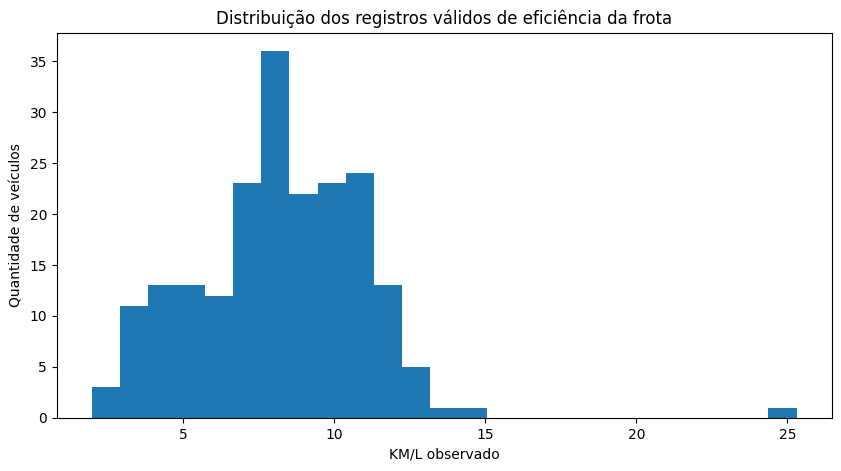

In [15]:
plot_data = fleet.loc[fleet["valid_efficiency"], "kmpl"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(plot_data, bins=25)
plt.xlabel("KM/L observado")
plt.ylabel("Quantidade de veículos")
plt.title("Distribuição dos registros válidos de eficiência da frota")
plt.show()


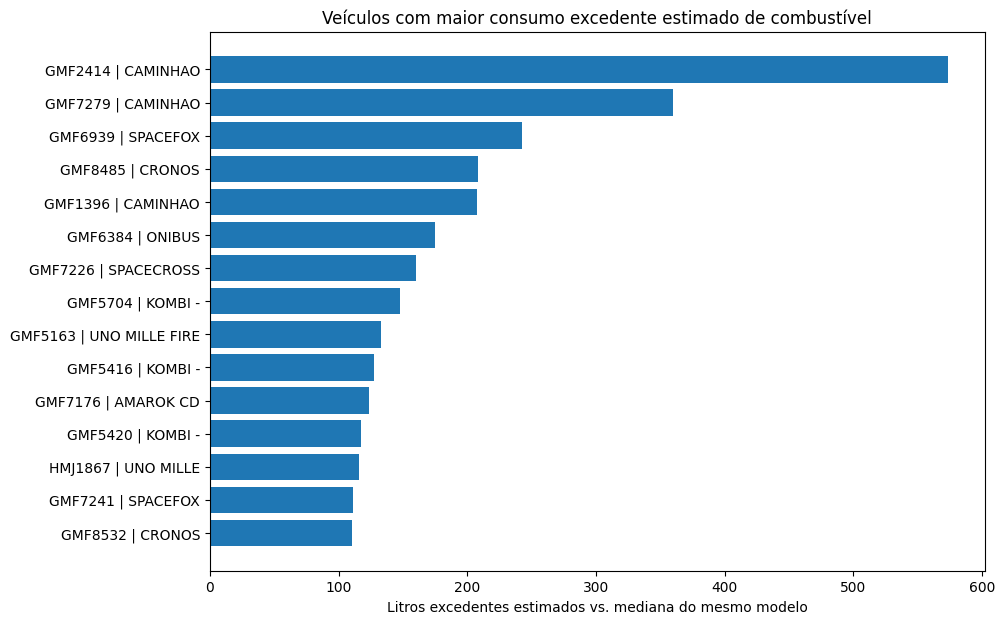

In [16]:
chart_peer = (
    fleet.loc[fleet["excess_liters_vs_peer"].notna()]
    .assign(excess_liters=lambda d: d["excess_liters_vs_peer"].clip(lower=0))
    .nlargest(15, "excess_liters")
    .sort_values("excess_liters")
)

plt.figure(figsize=(10, 7))
plt.barh(
    chart_peer["fleet_id"] + " | " + chart_peer["model"],
    chart_peer["excess_liters"]
)
plt.xlabel("Litros excedentes estimados vs. mediana do mesmo modelo")
plt.title("Veículos com maior consumo excedente estimado de combustível")
plt.show()


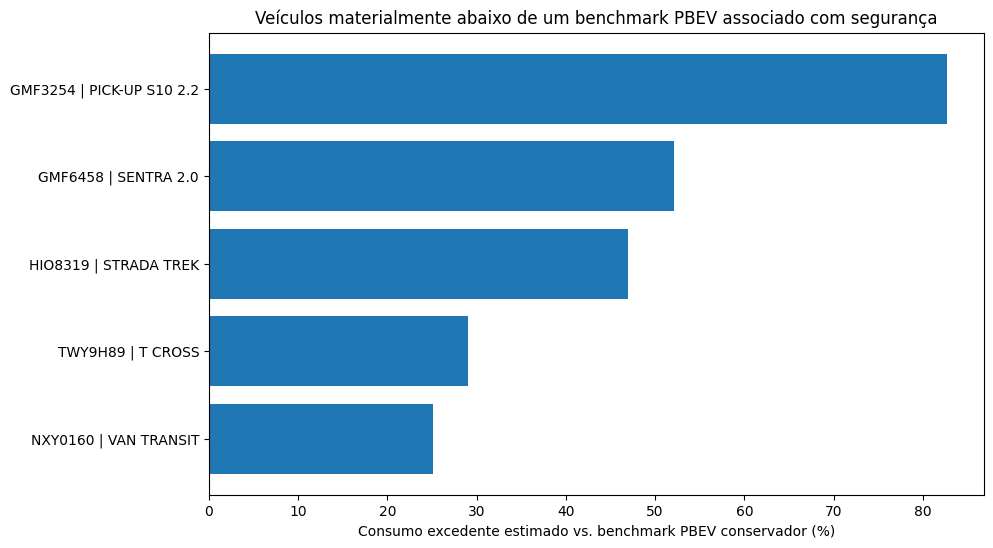

In [17]:
chart_public = (
    fleet.loc[fleet["public_waste_flag"]]
    .sort_values("public_overuse_pct_vs_min")
)

if len(chart_public):
    plt.figure(figsize=(10, 6))
    plt.barh(
        chart_public["fleet_id"] + " | " + chart_public["model"],
        chart_public["public_overuse_pct_vs_min"] * 100
    )
    plt.xlabel("Consumo excedente estimado vs. benchmark PBEV conservador (%)")
    plt.title("Veículos materialmente abaixo de um benchmark PBEV associado com segurança")
    plt.show()
else:
    print("Nenhum veículo ultrapassou o limite configurado de desperdício em relação ao PBEV.")


> **Observação:** esses gráficos mostram padrões e possíveis pontos de atenção, não uma previsão de consumo futuro. A validação com dados reais do cliente continua necessária.


## 13. Investigando um veículo individualmente

Depois de identificar um alerta na frota, vale examinar o registro de um veículo específico. A função a seguir reúne seus indicadores em um painel de leitura rápida: desempenho registrado, comparação entre pares, referência pública (quando disponível) e cenários de custo.

O exemplo usa automaticamente o veículo com maior volume positivo estimado frente aos pares. Para examinar outro veículo, informe seu identificador à função `vehicle_report`.


In [18]:
def vehicle_report(fleet_id: str):
    result = fleet.loc[fleet["fleet_id"].eq(fleet_id)].copy()
    if result.empty:
        raise KeyError(f"Veículo {fleet_id!r} não encontrado.")

    columns = [
        "fleet_id", "model", "km", "kmpl", "fuel_expense", "total_expense",
        "valid_efficiency", "quality_reason",
        "model_peer_count", "model_peer_median_kmpl",
        "peer_overuse_pct", "excess_liters_vs_peer",
        "normalized_efficiency_percentile", "peer_status",
        "pbev_model", "pbev_brand", "pbev_match_method",
        "pbev_min_kmpl", "pbev_median_kmpl", "pbev_max_kmpl",
        "public_overuse_pct_vs_min", "excess_liters_vs_public_min",
        "public_waste_flag",
        "peer_excess_cost_gasolina", "peer_excess_cost_etanol",
        "peer_excess_cost_diesel_s10"
    ]
    report = result[[column for column in columns if column in result.columns]]
    display(localize_table(report).T)


# Exemplo: veículo com maior volume excedente estimado em relação aos pares.
example_ids = (
    fleet.loc[fleet["excess_liters_vs_peer"] > 0]
    .sort_values("excess_liters_vs_peer", ascending=False)["fleet_id"]
)

if len(example_ids):
    vehicle_report(example_ids.iloc[0])


,3
Identificador do veículo,GMF2414
Modelo,CAMINHAO
Distância (km),"2,807.00"
KM/L calculado,2.43
Despesa com combustível,"7,789.40"
Despesa total,"8,715.26"
Eficiência válida,Sim
Motivo de qualidade,
Veículos comparáveis do mesmo modelo,8.00
Mediana KM/L do mesmo modelo,4.82


## 14. Exportação para outras etapas do Fleet Force

Além dos gráficos, a análise gera arquivos CSV com resultados organizados. Eles podem servir como base para testes de interface, relatórios, revisão dos alertas e estudos posteriores.

Os arquivos exportados preservam nomes técnicos de colunas para facilitar sua reutilização. A exportação não altera as fontes originais.


In [19]:
fleet_output = OUTPUT_DIR / "fleet_efficiency_analysis.csv"
quality_output = OUTPUT_DIR / "fleet_data_quality_flags.csv"
pbev_match_output = OUTPUT_DIR / "fleet_pbev_matches.csv"
anp_output = OUTPUT_DIR / "anp_mg_price_summary.csv"

fleet.to_csv(fleet_output, index=False)
quality_issues.to_csv(quality_output, index=False)
safe_matches.to_csv(pbev_match_output, index=False)
anp_price_summary.to_csv(anp_output)

print("Arquivos salvos:")
for path in [fleet_output, quality_output, pbev_match_output, anp_output]:
    print(" -", path)


Arquivos salvos:
 - /content/fleet_analysis_outputs/fleet_efficiency_analysis.csv
 - /content/fleet_analysis_outputs/fleet_data_quality_flags.csv
 - /content/fleet_analysis_outputs/fleet_pbev_matches.csv
 - /content/fleet_analysis_outputs/anp_mg_price_summary.csv


## 15. Síntese dos achados

A célula abaixo apresenta uma interpretação automática dos números calculados durante a execução. Leia os valores como **indicadores exploratórios**, sempre considerando a disponibilidade e a qualidade das informações.


In [20]:
print("INTERPRETAÇÃO DA FROTA")
print("-" * 80)

valid_count = int(fleet["valid_efficiency"].sum())
print(
    f"{valid_count} de {len(fleet)} veículos possuem dados suficientes e plausíveis "
    "para a análise de eficiência."
)

peer_comparable = fleet.loc[fleet["peer_overuse_pct"].notna()].copy()
if len(peer_comparable):
    positive_peer_excess = peer_comparable["excess_liters_vs_peer"].clip(lower=0).sum()
    print(
        f"Entre os veículos com pelo menos {MIN_MODEL_PEERS} comparáveis do mesmo modelo, "
        f"a soma do consumo excedente positivo estimado é de "
        f"{positive_peer_excess:,.1f} litros."
    )

public_comparable = fleet.loc[
    fleet["valid_efficiency"] & fleet["pbev_min_kmpl"].notna()
].copy()

if len(public_comparable):
    actual = (public_comparable["km"] / public_comparable["kmpl"]).sum()
    expected = (public_comparable["km"] / public_comparable["pbev_min_kmpl"]).sum()
    delta = actual - expected

    if delta > 0:
        print(
            "No subconjunto associado com segurança ao PBEV, a frota apresentou consumo "
            f"estimado acima do benchmark público conservador em {delta:,.1f} litros "
            f"({actual / expected - 1:.1%})."
        )
    else:
        print(
            "No subconjunto associado com segurança ao PBEV, a frota não apresentou "
            "consumo estimado acima do benchmark público conservador no agregado. "
            f"A diferença foi de {delta:,.1f} litros ({actual / expected - 1:.1%})."
        )

    print(
        f"{int(fleet['public_waste_flag'].sum())} veículos individuais ainda estão "
        f"mais de {PBEV_TOLERANCE:.0%} abaixo do respectivo benchmark PBEV conservador."
    )

print(
    "Os resultados do PBEV devem ser tratados como indicativos, e não como prova causal: "
    "ano-modelo, motor, tipo de combustível, rota, carga, manutenção e condições de "
    "condução não são totalmente controlados nesta análise."
)


INTERPRETAÇÃO DA FROTA
--------------------------------------------------------------------------------
201 de 217 veículos possuem dados suficientes e plausíveis para a análise de eficiência.
Entre os veículos com pelo menos 3 comparáveis do mesmo modelo, a soma do consumo excedente positivo estimado é de 4,614.2 litros.
No subconjunto associado com segurança ao PBEV, a frota não apresentou consumo estimado acima do benchmark público conservador no agregado. A diferença foi de -3,195.2 litros (-7.6%).
5 veículos individuais ainda estão mais de 20% abaixo do respectivo benchmark PBEV conservador.
Os resultados do PBEV devem ser tratados como indicativos, e não como prova causal: ano-modelo, motor, tipo de combustível, rota, carga, manutenção e condições de condução não são totalmente controlados nesta análise.


---

## 16. O que este estudo entrega ao Fleet Force?

| Frente do projeto | Contribuição atual | Próximo passo |
| --- | --- | --- |
| **US01 · Consolidar custos** | Reúne valores e quilometragem por veículo dentro do relatório estudado | Consolidar todas as categorias e aceitar planilhas de clientes |
| **US02 · Comparar despesas** | Compara eficiência com veículos de mesmo modelo e com referência pública limitada | Refinar os grupos por ano, versão, combustível e contexto de uso |
| **US03 · Identificar economias** | Estima litros excedentes e cenários financeiros | Validar causas, custos reais e potencial efetivamente recuperável |

### Conclusão

Este notebook é uma **prova de conceito de análise de consumo**, com dados públicos e regras interpretáveis. Ele mostra uma forma possível de transformar registros operacionais em prioridades de análise, mas ainda **não treina um modelo de Machine Learning** e **não confirma desperdícios reais**.

### Evoluções recomendadas

1. Testar a análise com uma planilha representativa de uma frota real e documentar os campos obrigatórios.
2. Melhorar a equivalência entre veículos comparáveis, incluindo combustível, ano, versão e uso.
3. Validar os alertas com informações de manutenção, rota e abastecimento.
4. Avaliar modelos preditivos somente quando houver dados suficientes e uma referência confiável para medir a qualidade das previsões.

### Glossário rápido

- **km/L:** quilômetros percorridos por litro de combustível; valores maiores tendem a representar maior eficiência em condições comparáveis.
- **Mediana:** valor central do grupo, menos influenciado por extremos do que uma média simples.
- **Benchmark:** valor de referência usado para orientar uma comparação.
- **Litros excedentes estimados:** diferença calculada em relação a um benchmark, não volume comprovadamente desperdiçado.
- **Alerta:** sinal para análise posterior, não diagnóstico conclusivo.

**Nota de reprodutibilidade:** mantenha os três arquivos de origem com seus nomes originais. Se forem publicados separadamente, documente suas fontes, período, licença e eventuais restrições de redistribuição. O PDF do pitch da Sprint 1 é usado apenas como contexto de produto e não como entrada dos cálculos.
